# Fraud Detection for Financial Risk Management

**Author:** Raja Perugu  
**Student ID:** F837G868

# Stage 1 — Data Loading and Initial Data Understanding

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("PS_20174392719_1491204439457_log.csv")

In [5]:
df

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.00,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.00,0.00,0,0
...,...,...,...,...,...,...,...,...,...,...,...
6362615,743,CASH_OUT,339682.13,C786484425,339682.13,0.00,C776919290,0.00,339682.13,1,0
6362616,743,TRANSFER,6311409.28,C1529008245,6311409.28,0.00,C1881841831,0.00,0.00,1,0
6362617,743,CASH_OUT,6311409.28,C1162922333,6311409.28,0.00,C1365125890,68488.84,6379898.11,1,0
6362618,743,TRANSFER,850002.52,C1685995037,850002.52,0.00,C2080388513,0.00,0.00,1,0


In [6]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


Investigating 3rd from above cell,we can see it is clearly marked as "isFraud",so if we take a look at whats happening check the balance changes


In [7]:
df.shape

(6362620, 11)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [9]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [10]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


# Observations 

#AMOUNT : The mean $179,862 is much higher than the median $74,872, and the maximum is extremely high so, transaction amounts are strongly right-skewed.

#OLDBALANCE(ORIGIN) : The mean is much higher than the median, and 25% of values are $0 so, sender balances are highly right-skewed with many zero balances.

#NEWBALNCE(ORIGIN) : Both the 25th and 50th percentiles are $0 so, at least 50% of transactions have a sender balance of $0 after the transaction.

#OLDBALANCE (DEST) : The mean is much higher than the median and the maximum is extremely large so, destination balances are highly right-skewed, with many zero balances.

#NEWBALNCE (DEST) : The mean is much higher than the median and the maximum is extremely large so, destination balances are highly right-skewed, with many zero balances.



#ISFRAUD : Only 0.129% of transactions are fraudulent, while about 99.87% are legitimate so, this is a severely imbalanced target variable, which will be an important challenge for our ML models.

#ISFLAGGEREDFRAUD : the existing isFlaggedFraud rule flags only about 16 transactions out of 6.36 million, an extremely small number so, we will later compare how effective this existing rule is against our ML models.

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df['type'].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [13]:
df.groupby('type')['isFraud'].sum()

type
CASH_IN        0
CASH_OUT    4116
DEBIT          0
PAYMENT        0
TRANSFER    4097
Name: isFraud, dtype: int64

All 8,213 fraudulent transactions occur in only two transaction types: CASH_OUT (4,116) and TRANSFER (4,097). No fraud is recorded in CASH_IN, PAYMENT, or DEBIT.

This tells us the number of fraud cases, but not yet the fraud rate

In [14]:
df.groupby('type')['isFraud'].mean() * 100

type
CASH_IN     0.000000
CASH_OUT    0.183955
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.768799
Name: isFraud, dtype: float64

TRANSFER appears to be the most fraud-prone transaction type, with about 0.77% of its transactions being fraudulent. This makes type potentially an important feature for our ML model.

REF : Practicle Statistics For Data Scientists by peter bruce,andrew bruce & peter gedeck - used Chapter -1 

# NEXT WEEK :

#Perfoming EDA and Visualizations
#Analyze transaction amounts, balances, time, and transaction types on fraud transactions
#Compare fraud vs. legitimate transactions with same variables.
#Identify important patterns.
#Begin feature engineering based on the EDA findings

In [15]:
!pip install pandoc


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


------------------------

# Stage 2 — Exploratory Data Analysis (EDA)

## 2.1 Transaction Amount Analysis

Question: Do fraudulent transactions have different transaction amounts from legitimate transactions?

In [16]:
amount_stats = df.groupby('isFraud')['amount'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

amount_stats

,count,mean,median,min,max
isFraud,,,,,
0,6354407,1.781970e+05,74684.72,0.01,92445516.64
1,8213,1.467967e+06,441423.44,0.00,10000000.00


Finding: Fraudulent transactions generally involve larger transaction amounts than legitimate transactions. The median fraud amount (~$441K) is substantially higher than the median legitimate amount (~$75K), suggesting that transaction amount may be an informative feature for fraud detection

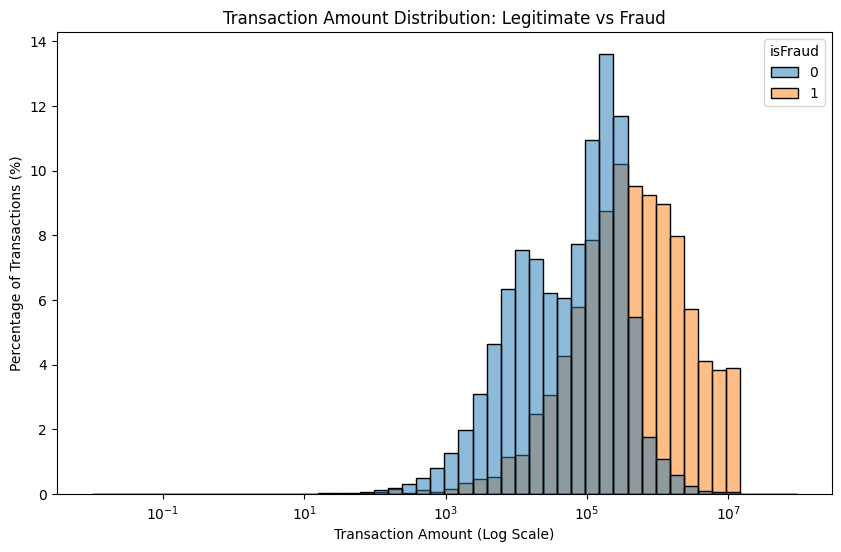

In [17]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='amount',
    hue='isFraud',
    bins=50,
    stat='percent',
    common_norm=False,
    log_scale=True
)

plt.title('Transaction Amount Distribution: Legitimate vs Fraud')
plt.xlabel('Transaction Amount (Log Scale)')
plt.ylabel('Percentage of Transactions (%)')
plt.show()

## 2.2 Sender Balance Analysis

Question: Does the sender's balance behave differently in fraudulent transactions compared with legitimate transactions?

In [18]:
sender_balance_stats = df.groupby('isFraud')[
    ['oldbalanceOrg', 'newbalanceOrig']
].agg(['mean', 'median'])

sender_balance_stats

oldbalanceOrg            newbalanceOrig       
                 mean     median           mean median
isFraud                                               
0        8.328287e+05   14069.00  855970.228109    0.0
1        1.649668e+06  438983.45  192392.631836    0.0

In [19]:
df['sender_balance_change'] = (
    df['oldbalanceOrg'] - df['newbalanceOrig']
)

In [20]:
df['sender_balance_error'] = (
    df['sender_balance_change'] - df['amount']
)

In [21]:
sender_error_stats = df.groupby('isFraud')['sender_balance_error'].agg(
    ['mean', 'median']
)

sender_error_stats

,mean,median
isFraud,,
0,-201338.558109,-69049.31
1,-10692.325265,0.00


In [22]:
zero_error_percentage = df.groupby('isFraud')['sender_balance_error'].apply(
    lambda x: (x.abs() < 0.01).mean() * 100
)

zero_error_percentage

isFraud
0    20.269806
1    99.452088
Name: sender_balance_error, dtype: float64

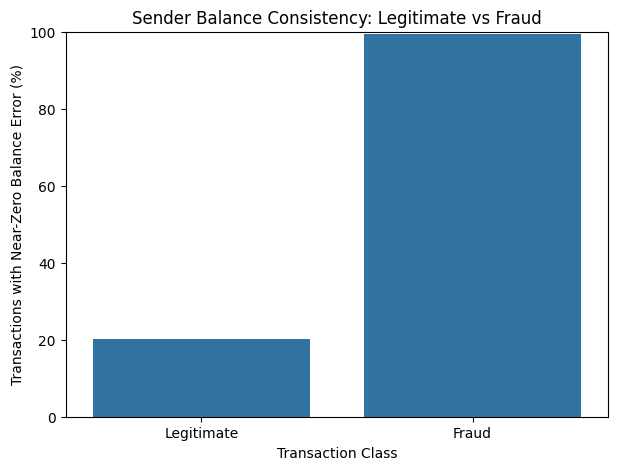

isFraud
0    20.269806
1    99.452088
Name: sender_balance_error, dtype: float64


In [23]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=['Legitimate', 'Fraud'],
    y=[zero_error_percentage[0], zero_error_percentage[1]]
)

plt.title('Sender Balance Consistency: Legitimate vs Fraud')
plt.xlabel('Transaction Class')
plt.ylabel('Transactions with Near-Zero Balance Error (%)')
plt.ylim(0, 100)


plt.show()

print(zero_error_percentage)

## 2.3 Receiver Balance Analysis

Question :
Does the receiver's balance behave differently in fraudulent transactions compared with legitimate transactions?

In [24]:
receiver_balance_stats = df.groupby('isFraud')[
    ['oldbalanceDest', 'newbalanceDest']
].agg(['mean', 'median'])

receiver_balance_stats

oldbalanceDest           newbalanceDest           
                  mean    median           mean     median
isFraud                                                   
0         1.101421e+06  133311.8   1.224926e+06  214881.70
1         5.442496e+05       0.0   1.279708e+06    4676.42

In [25]:
df['receiver_balance_change'] = (
    df['newbalanceDest'] - df['oldbalanceDest']
)

df['receiver_balance_error'] = (
    df['receiver_balance_change'] - df['amount']
)

In [26]:
receiver_error_stats = df.groupby('isFraud')['receiver_balance_error'].agg(
    ['mean', 'median']
)

receiver_error_stats

,mean,median
isFraud,,
0,-54692.231734,-3500.68
1,-732509.301069,-2231.46


In [27]:
receiver_zero_error_percentage = df.groupby('isFraud')['receiver_balance_error'].apply(lambda x: (x.abs() < 0.01).mean() * 100)

receiver_zero_error_percentage

isFraud
0    35.202561
1    43.772069
Name: receiver_balance_error, dtype: float64

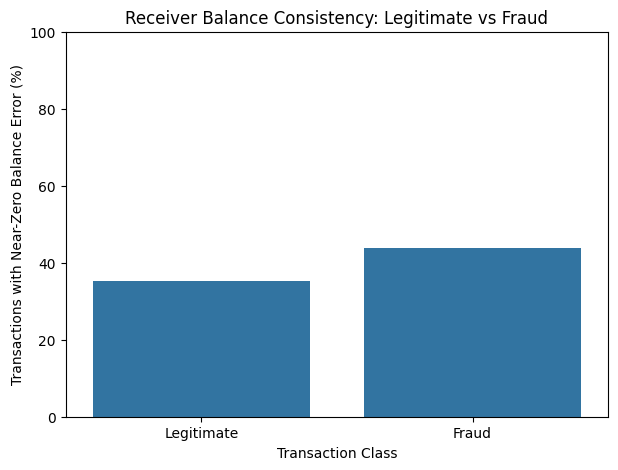

isFraud
0    35.202561
1    43.772069
Name: receiver_balance_error, dtype: float64


In [28]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=['Legitimate', 'Fraud'],
    y=[receiver_zero_error_percentage[0],
       receiver_zero_error_percentage[1]]
)

plt.title('Receiver Balance Consistency: Legitimate vs Fraud')
plt.xlabel('Transaction Class')
plt.ylabel('Transactions with Near-Zero Balance Error (%)')
plt.ylim(0, 100)

plt.show()

print(receiver_zero_error_percentage)

## 2.4 Fraud Patterns Over Time

Q : Does fraud occur uniformly over time, or are there periods where fraud is more concentrated?

In [29]:
time_fraud_stats = df.groupby('step')['isFraud'].agg(
    total_transactions='count',
    fraud_transactions='sum'
)

time_fraud_stats['fraud_rate'] = (
    time_fraud_stats['fraud_transactions'] /
    time_fraud_stats['total_transactions'] * 100
)

time_fraud_stats.head()

,total_transactions,fraud_transactions,fraud_rate
step,,,
1,2708,16,0.590842
2,1014,8,0.788955
3,552,4,0.724638
4,565,10,1.769912
5,665,6,0.902256


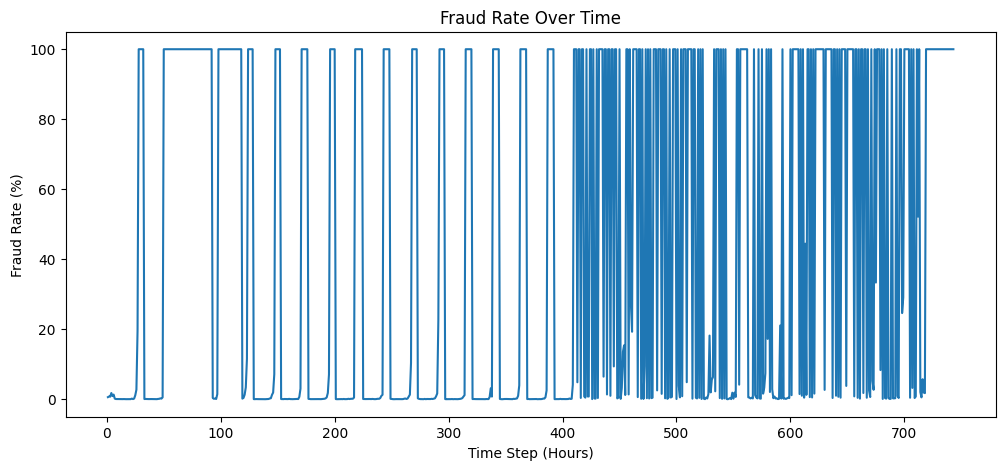

In [30]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=time_fraud_stats,
    x=time_fraud_stats.index,
    y='fraud_rate'
)

plt.title('Fraud Rate Over Time')
plt.xlabel('Time Step (Hours)')
plt.ylabel('Fraud Rate (%)')

plt.show()

In [31]:
print(time_fraud_stats.tail(20))

      total_transactions  fraud_transactions  fraud_rate
step                                                    
724                   14                  14       100.0
725                    4                   4       100.0
726                   22                  22       100.0
727                   12                  12       100.0
728                   10                  10       100.0
729                    4                   4       100.0
730                   28                  28       100.0
731                   16                  16       100.0
732                   10                  10       100.0
733                   10                  10       100.0
734                    8                   8       100.0
735                   12                  12       100.0
736                   14                  14       100.0
737                   10                  10       100.0
738                   10                  10       100.0
739                   10       

## 2.5 Correlation Analysis

In [32]:
correlation_features = df[
    ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
     'oldbalanceDest', 'newbalanceDest', 'isFraud']
]

correlation_matrix = correlation_features.corr()

correlation_matrix

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
step,1.000000,0.022373,-0.010058,-0.010299,0.027665,0.025888,0.031578
amount,0.022373,1.000000,-0.002762,-0.007861,0.294137,0.459304,0.076688
oldbalanceOrg,-0.010058,-0.002762,1.000000,0.998803,0.066243,0.042029,0.010154
newbalanceOrig,-0.010299,-0.007861,0.998803,1.000000,0.067812,0.041837,-0.008148
oldbalanceDest,0.027665,0.294137,0.066243,0.067812,1.000000,0.976569,-0.005885
newbalanceDest,0.025888,0.459304,0.042029,0.041837,0.976569,1.000000,0.000535
isFraud,0.031578,0.076688,0.010154,-0.008148,-0.005885,0.000535,1.000000


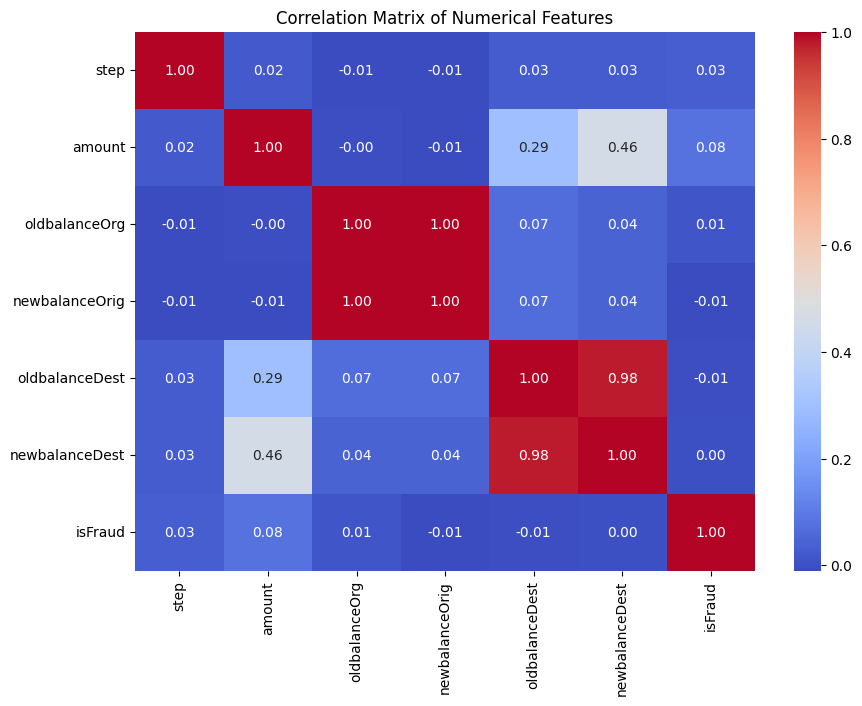

In [33]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Matrix of Numerical Features')
plt.show()

# Stage 3 — Feature Engineering

In [34]:
df['sender_balance_consistency'] = (
    df['sender_balance_error'].abs() < 0.01
).astype(int)

In [35]:
df[['sender_balance_error', 'sender_balance_consistency']].head()

,sender_balance_error,sender_balance_consistency
0,1.455192e-11,1
1,-1.136868e-12,1
2,0.000000e+00,1
3,0.000000e+00,1
4,0.000000e+00,1


In [36]:
type_encoded = pd.get_dummies(df['type'], prefix='type', dtype=int)

type_encoded.head()

,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,0,0,0,1,0
1,0,0,0,1,0
2,0,0,0,0,1
3,0,1,0,0,0
4,0,0,0,1,0


In [37]:
df = pd.concat([df, type_encoded], axis=1)

In [38]:
df[['type', 'type_CASH_IN', 'type_CASH_OUT',
    'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']].head()

,type,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,PAYMENT,0,0,0,1,0
1,PAYMENT,0,0,0,1,0
2,TRANSFER,0,0,0,0,1
3,CASH_OUT,0,1,0,0,0
4,PAYMENT,0,0,0,1,0


In [39]:
df['hour_of_day'] = (df['step'] - 1) % 24

In [40]:
df[['step', 'hour_of_day']].head(30)

,step,hour_of_day
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0
5,1,0
6,1,0
7,1,0
8,1,0
9,1,0


In [41]:
df[['step', 'hour_of_day']].drop_duplicates().head(30)

,step,hour_of_day
0,1,0
2708,2,1
3722,3,2
4274,4,3
4839,5,4
5504,6,5
7164,7,6
14001,8,7
35098,9,8
72726,10,9


In [42]:
print("Unique nameOrig:", df['nameOrig'].nunique())
print("Unique nameDest:", df['nameDest'].nunique())

Unique nameOrig: 6353307
Unique nameDest: 2722362


#_Do not use the raw nameOrig and nameDest IDs directly as model features,we can still keep them temporarily in the dataframe because later, if we want, we can derive behavioral features from them

#_For our project, I recommend that we do not use isFlaggedFraud as an input feature for Random Forest/XGBoost

# Variables

amount and balance columns - keep
sender_balance_error - keep
sender_balance_consistency - keep
encoded type_* columns - keep
step → keep
hour_of_day - keep
nameOrig, nameDest - excluded
original text type - excluded after encoding
isFlaggedFraud - keep only for baseline comparison
isFraud - target, not input

# Final Modeling Features

In [43]:
features = [
    'step',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest',
    'sender_balance_error',
    'sender_balance_consistency',
    'hour_of_day',
    'type_CASH_IN',
    'type_CASH_OUT',
    'type_DEBIT',
    'type_PAYMENT',
    'type_TRANSFER'
]

X = df[features]
y = df['isFraud']

In [44]:
print(X.shape)
print(y.shape)
X.head()

(6362620, 14)
(6362620,)


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,sender_balance_error,sender_balance_consistency,hour_of_day,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,9839.64,170136.0,160296.36,0.0,0.0,1.455192e-11,1,0,0,0,0,1,0
1,1,1864.28,21249.0,19384.72,0.0,0.0,-1.136868e-12,1,0,0,0,0,1,0
2,1,181.00,181.0,0.00,0.0,0.0,0.000000e+00,1,0,0,0,0,0,1
3,1,181.00,181.0,0.00,21182.0,0.0,0.000000e+00,1,0,0,1,0,0,0
4,1,11668.14,41554.0,29885.86,0.0,0.0,0.000000e+00,1,0,0,0,0,1,0


In [45]:
X.isnull().sum()

step                          0
amount                        0
oldbalanceOrg                 0
newbalanceOrig                0
oldbalanceDest                0
newbalanceDest                0
sender_balance_error          0
sender_balance_consistency    0
hour_of_day                   0
type_CASH_IN                  0
type_CASH_OUT                 0
type_DEBIT                    0
type_PAYMENT                  0
type_TRANSFER                 0
dtype: int64

## Feature Engineering Summary

- Created `sender_balance_error` to measure whether the sender's balance change matches the transaction amount.
- Created `sender_balance_consistency` because EDA showed a strong difference between fraudulent and legitimate transactions.
- One-hot encoded the `type` column into numerical transaction-type features.
- Created `hour_of_day` from `step` to capture repeating 24-hour transaction patterns while retaining the original `step`.
- Excluded `nameOrig` and `nameDest` from the modeling feature set because they contain millions of unique identifiers.
- Excluded `isFlaggedFraud` as a predictor because it represents the existing rule-based fraud flag and will be used only as a baseline/reference.
- Final modeling data contains 14 predictor features with no missing values.

# Stage 4 — Data Splitting and Class Imbalance Handling

In [46]:
!pip install scikit-learn imbalanced-learn


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [47]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score
)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

## 4.1 Train-Test Split

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [49]:
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTraining fraud rate:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTest fraud rate:")
print(y_test.value_counts(normalize=True) * 100)

Training shape: (5090096, 14)
Test shape: (1272524, 14)

Training fraud rate:
isFraud
0    99.870926
1     0.129074
Name: proportion, dtype: float64

Test fraud rate:
isFraud
0    99.870887
1     0.129113
Name: proportion, dtype: float64


## 4.2 Class Weighting

In [50]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=y_train
)

print("Legitimate class weight:", class_weights[0])
print("Fraud class weight:", class_weights[1])

Legitimate class weight: 0.5006462050159672
Fraud class weight: 387.37412480974126


In [51]:
from sklearn.linear_model import LogisticRegression

weighted_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

weighted_model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [52]:
weighted_model_predictions = weighted_model.predict(X_test)

weighted_model_predictions[:20]

array([0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [53]:
weighted_model_probabilities = weighted_model.predict_proba(X_test)[:, 1]

weighted_model_probabilities[:20]

array([4.47314870e-02, 1.61638246e-03, 1.12129808e-05, 1.00374748e-02,
       1.01694196e-02, 7.61967787e-01, 1.32294407e-02, 9.61117629e-02,
       8.61268794e-03, 2.46761970e-02, 2.42501902e-03, 1.36624744e-01,
       1.18209563e-02, 1.20500414e-02, 3.53575550e-06, 4.46554932e-01,
       1.17017063e-02, 3.69747159e-02, 1.37714961e-05, 3.52085494e-02])

In [54]:
weighted_model_precision = precision_score(
    y_test,
    weighted_model_predictions
)

weighted_model_recall = recall_score(
    y_test,
    weighted_model_predictions
)

weighted_model_f1 = f1_score(
    y_test,
    weighted_model_predictions
)

weighted_model_auprc = average_precision_score(
    y_test,
    weighted_model_probabilities
)

weighted_model_confusion_matrix = confusion_matrix(
    y_test,
    weighted_model_predictions
)

In [55]:
print("Precision:", weighted_model_precision)
print("Recall:", weighted_model_recall)
print("F1 Score:", weighted_model_f1)
print("AUPRC:", weighted_model_auprc)
print("\nConfusion Matrix:")
print(weighted_model_confusion_matrix)


Precision: 0.02837264729592373
Recall: 0.985392574558734
F1 Score: 0.055157141640405416
AUPRC: 0.6571497679002948

Confusion Matrix:
[[1215438   55443]
 [     24    1619]]


#Class weighting achieved extremely high recall of 98.54%, detecting 1,619 of 1,643 fraud cases. However, precision was only 2.84% because 55,443 legitimate transactions were falsely flagged as fraud. This shows that class weighting strongly improves fraud detection but produces too many false positives at the default threshold.

## 4.3 Random Undersampling

In [56]:
undersampler = RandomUnderSampler(
    random_state=42
)

X_train_undersampled, y_train_undersampled = undersampler.fit_resample(
    X_train,
    y_train
)

In [57]:
print("Original training shape:", X_train.shape)
print("Undersampled training shape:", X_train_undersampled.shape)

print("\nUndersampled class distribution:")
print(y_train_undersampled.value_counts())

Original training shape: (5090096, 14)
Undersampled training shape: (13140, 14)

Undersampled class distribution:
isFraud
0    6570
1    6570
Name: count, dtype: int64


In [58]:
from sklearn.linear_model import LogisticRegression

undersampled_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

undersampled_model.fit(
    X_train_undersampled,
    y_train_undersampled
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [59]:
undersampled_model_predictions = undersampled_model.predict(X_test)

undersampled_model_probabilities = undersampled_model.predict_proba(X_test)[:, 1]

In [60]:
undersampled_model_precision = precision_score(
    y_test,
    undersampled_model_predictions
)

undersampled_model_recall = recall_score(
    y_test,
    undersampled_model_predictions
)

undersampled_model_f1 = f1_score(
    y_test,
    undersampled_model_predictions
)

undersampled_model_auprc = average_precision_score(
    y_test,
    undersampled_model_probabilities
)

undersampled_model_confusion_matrix = confusion_matrix(
    y_test,
    undersampled_model_predictions
)

In [61]:
print("Precision:", undersampled_model_precision)
print("Recall:", undersampled_model_recall)
print("F1 Score:", undersampled_model_f1)
print("AUPRC:", undersampled_model_auprc)

print("\nConfusion Matrix:")
print(undersampled_model_confusion_matrix)

Precision: 0.02815510430383256
Recall: 0.9890444309190505
F1 Score: 0.05475159621961286
AUPRC: 0.661534449081495

Confusion Matrix:
[[1214790   56091]
 [     18    1625]]


#Undersampling slightly improved recall and AUPRC, but slightly reduced precision and F1 compared with class weighting. Overall, the two methods performed very similarly.

## 4.3 Random Undersampling

In [62]:
oversampler = RandomOverSampler(
    sampling_strategy=0.10,
    random_state=42
)

X_train_oversampled, y_train_oversampled = oversampler.fit_resample(
    X_train,
    y_train
)

In [63]:
print("Original training shape:", X_train.shape)
print("Oversampled training shape:", X_train_oversampled.shape)

print("\nOversampled class distribution:")
print(y_train_oversampled.value_counts())

Original training shape: (5090096, 14)
Oversampled training shape: (5591878, 14)

Oversampled class distribution:
isFraud
0    5083526
1     508352
Name: count, dtype: int64


In [64]:
oversampled_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

oversampled_model.fit(
    X_train_oversampled,
    y_train_oversampled
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [65]:
oversampled_model_predictions = oversampled_model.predict(X_test)

oversampled_model_probabilities = oversampled_model.predict_proba(X_test)[:, 1]

In [66]:
oversampled_model_precision = precision_score(
    y_test,
    oversampled_model_predictions
)

oversampled_model_recall = recall_score(
    y_test,
    oversampled_model_predictions
)

oversampled_model_f1 = f1_score(
    y_test,
    oversampled_model_predictions
)

oversampled_model_auprc = average_precision_score(
    y_test,
    oversampled_model_probabilities
)

oversampled_model_confusion_matrix = confusion_matrix(
    y_test,
    oversampled_model_predictions
)

In [67]:
print("Precision:", oversampled_model_precision)
print("Recall:", oversampled_model_recall)
print("F1 Score:", oversampled_model_f1)
print("AUPRC:", oversampled_model_auprc)

print("\nConfusion Matrix:")
print(oversampled_model_confusion_matrix)

Precision: 0.11582796724699897
Recall: 0.8867924528301887
F1 Score: 0.20489382646603854
AUPRC: 0.6896925723208679

Confusion Matrix:
[[1259759   11122]
 [    186    1457]]


## 4.5 Imbalance Handling Conclusion

Random oversampling produced the best overall balance among the three methods. It achieved the highest precision, F1-score, and AUPRC while greatly reducing false positives, although recall decreased compared with class weighting and undersampling.

# Stage 5 — Model Development

## 5.1 Random Forest

In [68]:
from sklearn.ensemble import RandomForestClassifier

In [69]:
random_forest_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train_oversampled,
    y_train_oversampled
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total nu

In [70]:
random_forest_predictions = random_forest_model.predict(X_test)

random_forest_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

In [71]:
random_forest_precision = precision_score(
    y_test,
    random_forest_predictions
)

random_forest_recall = recall_score(
    y_test,
    random_forest_predictions
)

random_forest_f1 = f1_score(
    y_test,
    random_forest_predictions
)

random_forest_auprc = average_precision_score(
    y_test,
    random_forest_probabilities
)

random_forest_confusion_matrix = confusion_matrix(
    y_test,
    random_forest_predictions
)

### Random Forest Results

In [72]:
print("Precision:", random_forest_precision)
print("Recall:", random_forest_recall)
print("F1 Score:", random_forest_f1)
print("AUPRC:", random_forest_auprc)

print("\nConfusion Matrix:")
print(random_forest_confusion_matrix)

Precision: 1.0
Recall: 0.9975654290931223
F1 Score: 0.9987812309567337
AUPRC: 0.9987030653636816

Confusion Matrix:
[[1270881       0]
 [      4    1639]]


## 5.2 XGBoost

In [73]:
!pip install xgboost

from xgboost import XGBClassifier


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [74]:
xgboost_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

xgboost_model.fit(
    X_train_oversampled,
    y_train_oversampled
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [75]:
xgboost_predictions = xgboost_model.predict(X_test)

xgboost_probabilities = xgboost_model.predict_proba(X_test)[:, 1]

xgboost_precision = precision_score(
    y_test,
    xgboost_predictions
)

xgboost_recall = recall_score(
    y_test,
    xgboost_predictions
)

xgboost_f1 = f1_score(
    y_test,
    xgboost_predictions
)

xgboost_auprc = average_precision_score(
    y_test,
    xgboost_probabilities
)

xgboost_confusion_matrix = confusion_matrix(
    y_test,
    xgboost_predictions
)

### XGBoost Results

In [76]:
print("Precision:", xgboost_precision)
print("Recall:", xgboost_recall)
print("F1 Score:", xgboost_f1)
print("AUPRC:", xgboost_auprc)

print("\nConfusion Matrix:")
print(xgboost_confusion_matrix)

Precision: 0.981437125748503
Recall: 0.9975654290931223
F1 Score: 0.9894355568970722
AUPRC: 0.9986700994954985

Confusion Matrix:
[[1270850      31]
 [      4    1639]]


# Stage 6 — Model Evaluation and Final Model Selection( upcomming)

In [79]:
random_forest_false_negative_mask = (
    (y_test.to_numpy() == 1) &
    (random_forest_predictions == 0)
)

In [82]:
random_forest_false_negatives = df.loc[
    y_test.index[random_forest_false_negative_mask],
    [
        'step',
        'type',
        'amount',
        'oldbalanceOrg',
        'newbalanceOrig',
        'oldbalanceDest',
        'newbalanceDest',
        'sender_balance_error',
        'sender_balance_consistency'
    ]
].copy()

In [83]:
random_forest_false_negatives['fraud_probability'] = (
    random_forest_probabilities[random_forest_false_negative_mask]
)

random_forest_false_negatives

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,sender_balance_error,sender_balance_consistency,fraud_probability
77745,10,CASH_OUT,277970.88,0.00,0.0,0.00,277970.88,-277970.88,0,0.104679
543928,21,CASH_OUT,23292.30,0.00,0.0,392364.62,415656.92,-23292.30,0,0.000176
217978,13,TRANSFER,123194.95,79466.45,0.0,535933.16,263908.84,-43728.50,0,0.000000
14861,8,CASH_OUT,181728.11,0.00,0.0,11397.00,184477.77,-181728.11,0,0.106854


In [84]:
df.groupby('isFraud')['sender_balance_consistency'].value_counts(normalize=True) * 100

isFraud  sender_balance_consistency
0        0                             79.730194
         1                             20.269806
1        1                             99.452088
         0                              0.547912
Name: proportion, dtype: float64

99.45% of fraud transactions have sender_balance_consistency = 1, while all 4 fraud cases missed by Random Forest had sender_balance_consistency = 0, showing that the missed cases were unusual compared with the normal fraud pattern.

In [85]:
xgboost_false_positive_mask = (
    (y_test.to_numpy() == 0) &
    (xgboost_predictions == 1)
)

In [87]:
xgboost_false_positives = df.loc[
    y_test.index[xgboost_false_positive_mask],
    [
        'step',
        'type',
        'amount',
        'oldbalanceOrg',
        'newbalanceOrig',
        'oldbalanceDest',
        'newbalanceDest',
        'sender_balance_error',
        'sender_balance_consistency'
    ]
].copy()

In [88]:
xgboost_false_positives['fraud_probability'] = (
    xgboost_probabilities[xgboost_false_positive_mask]
)

xgboost_false_positives.head(10)

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,sender_balance_error,sender_balance_consistency,fraud_probability
4418741,322,DEBIT,122.38,124.0,1.62,833900.3,834022.68,0.00,1,0.914279
355488,17,CASH_OUT,426650.49,0.0,0.00,0.0,426650.49,-426650.49,0,0.579201
2269379,187,CASH_OUT,281580.08,0.0,0.00,0.0,281580.08,-281580.08,0,0.683517
183851,13,CASH_OUT,306586.09,0.0,0.00,0.0,452711.36,-306586.09,0,0.541491
866908,42,TRANSFER,1694647.01,0.0,0.00,0.0,1694647.01,-1694647.01,0,0.934980
690113,36,CASH_OUT,265837.60,0.0,0.00,0.0,265837.60,-265837.60,0,0.539295
217278,13,CASH_OUT,262279.63,0.0,0.00,0.0,262279.63,-262279.63,0,0.541491
715901,37,CASH_OUT,96616.39,0.0,0.00,0.0,96616.39,-96616.39,0,0.551991
564078,22,CASH_OUT,95872.78,0.0,0.00,0.0,95872.78,-95872.78,0,0.595786
193780,13,CASH_OUT,391183.62,0.0,0.00,0.0,391183.62,-391183.62,0,0.541491


In [89]:
xgboost_false_negative_mask = (
    (y_test.to_numpy() == 1) &
    (xgboost_predictions == 0)
)

In [90]:
xgboost_false_negatives = df.loc[
    y_test.index[xgboost_false_negative_mask],
    [
        'step',
        'type',
        'amount',
        'oldbalanceOrg',
        'newbalanceOrig',
        'oldbalanceDest',
        'newbalanceDest',
        'sender_balance_error',
        'sender_balance_consistency'
    ]
].copy()

In [91]:
xgboost_false_negatives['fraud_probability'] = (
    xgboost_probabilities[xgboost_false_negative_mask]
)

xgboost_false_negatives

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,sender_balance_error,sender_balance_consistency,fraud_probability
77745,10,CASH_OUT,277970.88,0.00,0.0,0.00,277970.88,-277970.88,0,0.122676
543928,21,CASH_OUT,23292.30,0.00,0.0,392364.62,415656.92,-23292.30,0,0.000054
217978,13,TRANSFER,123194.95,79466.45,0.0,535933.16,263908.84,-43728.50,0,0.000027
14861,8,CASH_OUT,181728.11,0.00,0.0,11397.00,184477.77,-181728.11,0,0.075555


Both Random Forest and XGBoost have same fraud cases. These fraud transactions did not follow the sender-balance pattern that most fraud transactions in the dataset had.

In [92]:
xgboost_false_positives['sender_balance_consistency'].value_counts(normalize=True) * 100

sender_balance_consistency
0    83.870968
1    16.129032
Name: proportion, dtype: float64

In [93]:
xgboost_false_positives['type'].value_counts(normalize=True) * 100

type
CASH_OUT    83.870968
TRANSFER     9.677419
DEBIT        6.451613
Name: proportion, dtype: float64

Most XGBoost false positives were CASH_OUT transactions with sender_balance_consistency = 0, showing that XGBoost often treated this unusual legitimate pattern as suspicious and incorrectly flagged it as fraud.

### Time Based Splitting

In [94]:
time_split_point = int(len(df) * 0.80)
df_time_sorted = df.sort_values('step').reset_index(drop=True)

In [95]:
time_train = df_time_sorted.iloc[:time_split_point]
time_test = df_time_sorted.iloc[time_split_point:]

In [96]:
X_train_time = time_train[features]
y_train_time = time_train['isFraud']

X_test_time = time_test[features]
y_test_time = time_test['isFraud']

In [98]:
print("Training shape:", X_train_time.shape)
print("Test shape:", X_test_time.shape)

print("\nTraining step range:",
      time_train['step'].min(), "to", time_train['step'].max())

print("Test step range:",
      time_test['step'].min(), "to", time_test['step'].max())

Training shape: (5090096, 14)
Test shape: (1272524, 14)

Training step range: 1 to 355
Test step range: 355 to 743


In [99]:
print("\nTraining fraud rate:")
print(y_train_time.value_counts(normalize=True) * 100)

print("\nTest fraud rate:")
print(y_test_time.value_counts(normalize=True) * 100)


Training fraud rate:
isFraud
0    99.922222
1     0.077778
Name: proportion, dtype: float64

Test fraud rate:
isFraud
0    99.665704
1     0.334296
Name: proportion, dtype: float64


In [100]:
time_split_step = 355

time_train = df[df['step'] < time_split_step]
time_test = df[df['step'] >= time_split_step]

In [101]:
X_train_time = time_train[features]
y_train_time = time_train['isFraud']

X_test_time = time_test[features]
y_test_time = time_test['isFraud']

print("Training shape:", X_train_time.shape)
print("Test shape:", X_test_time.shape)

print("\nTraining step range:",
      time_train['step'].min(), "to", time_train['step'].max())

print("Test step range:",
      time_test['step'].min(), "to", time_test['step'].max())

Training shape: (5069097, 14)
Test shape: (1293523, 14)

Training step range: 1 to 354
Test step range: 355 to 743


In [102]:
print("\nTraining fraud rate:")
print(y_train_time.value_counts(normalize=True) * 100)

print("\nTest fraud rate:")
print(y_test_time.value_counts(normalize=True) * 100)


Training fraud rate:
isFraud
0    99.921978
1     0.078022
Name: proportion, dtype: float64

Test fraud rate:
isFraud
0    99.670821
1     0.329179
Name: proportion, dtype: float64
